# VGG16 Fine-Tuning on MNIST

Lab 2 - PyTorch computer vision on GPU.

Status: Kaggle training, restored-checkpoint validation, and comparison with CNN and Faster R-CNN completed. The test set remains unevaluated.


## 1. Kaggle environment and reproducibility

Attach the professor's [MNIST dataset](https://www.kaggle.com/datasets/hojjatk/mnist-dataset) and enable a GPU in Kaggle. Run the cells in order. No package upgrades are needed before checking the installed environment.

These setup cells are shared across all five notebooks. Seed 42 and the same official training indices define the common partitions. Training and evaluation run only in Kaggle.


In [1]:
from pathlib import Path
import gzip
import hashlib
import importlib.metadata
import json
import platform
import random
import struct
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

assert torch.cuda.is_available(), 'Enable a GPU in Kaggle before continuing.'
device = torch.device('cuda:0')
RESULTS_DIR = Path('/kaggle/working/results')
PLOTS_DIR = Path('/kaggle/working/plots')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

environment = {
    'python': platform.python_version(),
    'gpu': torch.cuda.get_device_name(device),
    'cuda_runtime': torch.version.cuda,
    'seed': SEED,
    'packages': {name: importlib.metadata.version(name) for name in
                 ['torch', 'torchvision', 'numpy', 'pandas', 'scikit-learn', 'matplotlib']},
}
print(json.dumps(environment, indent=2))
(RESULTS_DIR / 'mnist_environment.json').write_text(json.dumps(environment, indent=2))


{
  "python": "3.13.15",
  "gpu": "Tesla T4",
  "cuda_runtime": "12.8",
  "seed": 42,
  "packages": {
    "torch": "2.11.0+cu128",
    "torchvision": "0.26.0+cu128",
    "numpy": "2.1.3",
    "pandas": "2.3.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0"
  }
}


272

### GPU smoke check

A small synthetic forward/backward pass checks GPU execution. It does not train a lab model or access MNIST. Random seeds are reset afterwards.


In [2]:
smoke_model = nn.Sequential(nn.Flatten(), nn.Linear(28 * 28, 10)).to(device)
smoke_x = torch.rand(8, 1, 28, 28, device=device)
smoke_y = torch.arange(8, device=device)
smoke_loss = nn.CrossEntropyLoss()(smoke_model(smoke_x), smoke_y)
smoke_loss.backward()
assert torch.isfinite(smoke_loss)
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in smoke_model.parameters())
print('PASS: GPU forward pass, cross-entropy, and finite gradients.')
del smoke_model, smoke_x, smoke_y, smoke_loss
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


PASS: GPU forward pass, cross-entropy, and finite gradients.


## 2. Locate and validate MNIST

The loader reads the official IDX image and label files, including gzip copies. If Kaggle contains duplicate copies, their decompressed contents must agree. File hashes are saved so the other notebooks can verify they use the same data.


In [3]:
INPUT_DIR = Path('/kaggle/input')
file_names = {
    'train_images': 'train-images-idx3-ubyte',
    'train_labels': 'train-labels-idx1-ubyte',
    'test_images': 't10k-images-idx3-ubyte',
    'test_labels': 't10k-labels-idx1-ubyte',
}

def read_bytes(path):
    return gzip.decompress(path.read_bytes()) if path.suffix == '.gz' else path.read_bytes()

source_paths = {}
source_hashes = {}
for key, name in file_names.items():
    alternatives = {name, name.replace('-idx', '.idx')}
    accepted_names = alternatives | {n + '.gz' for n in alternatives}
    matches = sorted(p for p in INPUT_DIR.rglob('*') if p.is_file() and p.name in accepted_names)
    assert matches, f'Missing {name}. Attach the MNIST dataset specified in the lab.'
    hashes = {hashlib.sha256(read_bytes(p)).hexdigest() for p in matches}
    assert len(hashes) == 1, f'Conflicting copies of {name}: {matches}'
    source_paths[key] = matches[0]
    source_hashes[key] = hashes.pop()
    print(f'{key}: {matches[0]} ({len(matches)} matching copies)')

def read_idx(path):
    raw = read_bytes(path)
    assert len(raw) >= 8, f'Incomplete IDX header: {path}'
    magic, count = struct.unpack('>II', raw[:8])
    if magic == 2051:
        rows, cols = struct.unpack('>II', raw[8:16])
        assert (rows, cols) == (28, 28)
        assert len(raw) == 16 + count * rows * cols
        return np.frombuffer(raw, dtype=np.uint8, offset=16).reshape(count, rows, cols).copy()
    assert magic == 2049, f'Unexpected IDX magic number: {magic}'
    assert len(raw) == 8 + count
    return np.frombuffer(raw, dtype=np.uint8, offset=8).copy()

official_train_images = read_idx(source_paths['train_images'])
official_train_labels = read_idx(source_paths['train_labels'])
official_test_images = read_idx(source_paths['test_images'])
official_test_labels = read_idx(source_paths['test_labels'])
assert official_train_images.shape == (60000, 28, 28)
assert official_test_images.shape == (10000, 28, 28)
assert official_train_labels.shape == (60000,)
assert official_test_labels.shape == (10000,)
for labels in (official_train_labels, official_test_labels):
    assert np.array_equal(np.unique(labels), np.arange(10))
print('Official training images:', official_train_images.shape)
print('Official test images:', official_test_images.shape)
print('Pixel dtype:', official_train_images.dtype)
print('Training pixel range:', official_train_images.min(), official_train_images.max())
print('PASS: IDX sizes, image dimensions, and label ranges.')


train_images: /kaggle/input/datasets/hojjatk/mnist-dataset/train-images-idx3-ubyte/train-images-idx3-ubyte (2 matching copies)
train_labels: /kaggle/input/datasets/hojjatk/mnist-dataset/train-labels-idx1-ubyte/train-labels-idx1-ubyte (2 matching copies)
test_images: /kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte (2 matching copies)
test_labels: /kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte (2 matching copies)
Official training images: (60000, 28, 28)
Official test images: (10000, 28, 28)
Pixel dtype: uint8
Training pixel range: 0 255
PASS: IDX sizes, image dimensions, and label ranges.


## 3. Shared train, validation, and test partitions

Split the official training set into 54,000 training and 6,000 validation images, stratified by digit. Keep the 10,000 official test images separate. Test labels are used here only for structural checks and partition counts, never for model selection.

The split manifest identifies images by their original index and source partition. Indices from the official train and test files belong to different namespaces. A hash of the manifest allows exact cross-notebook comparison.


In [4]:
train_indices, validation_indices = train_test_split(
    np.arange(len(official_train_labels)),
    test_size=6000,
    random_state=SEED,
    stratify=official_train_labels,
)
train_indices = np.sort(train_indices)
validation_indices = np.sort(validation_indices)
test_indices = np.arange(len(official_test_labels))
assert len(np.intersect1d(train_indices, validation_indices)) == 0
assert np.array_equal(np.sort(np.concatenate([train_indices, validation_indices])), np.arange(60000))

split_manifest = pd.concat([
    pd.DataFrame({'split': 'train', 'source': 'official_train', 'source_index': train_indices}),
    pd.DataFrame({'split': 'validation', 'source': 'official_train', 'source_index': validation_indices}),
    pd.DataFrame({'split': 'test', 'source': 'official_test', 'source_index': test_indices}),
], ignore_index=True)
assert not split_manifest.duplicated(['source', 'source_index']).any()
manifest_text = split_manifest.to_csv(index=False, lineterminator='\n')
split_hash = hashlib.sha256(manifest_text.encode()).hexdigest()
(RESULTS_DIR / 'mnist_split_manifest.csv').write_text(manifest_text)

split_labels = {
    'train': official_train_labels[train_indices],
    'validation': official_train_labels[validation_indices],
    'test': official_test_labels,
}
class_counts = pd.DataFrame({name: np.bincount(labels, minlength=10) for name, labels in split_labels.items()})
class_counts.index.name = 'digit'
assert (class_counts > 0).all().all()
display(class_counts)
class_counts.to_csv(RESULTS_DIR / 'mnist_split_class_counts.csv')
print('Partition sizes:', {name: len(labels) for name, labels in split_labels.items()})
print('Split SHA256:', split_hash)
print('PASS: disjoint source indices, full coverage, and all ten classes in each partition.')


,train,validation,test
digit,,,
0,5331,592,980
1,6068,674,1135
2,5362,596,1032
3,5518,613,1010
4,5258,584,982
5,4879,542,892
6,5326,592,958
7,5638,627,1028
8,5266,585,974


Partition sizes: {'train': 54000, 'validation': 6000, 'test': 10000}
Split SHA256: d42d6480e8042889f5d4e6ae98011dc1f7014582fc33baf093d8a5d847f395f4
PASS: disjoint source indices, full coverage, and all ten classes in each partition.


### Training examples and class distribution

Inspect training images only. No balancing is planned unless the observed data justify it; the lab does not request an oversampling experiment.


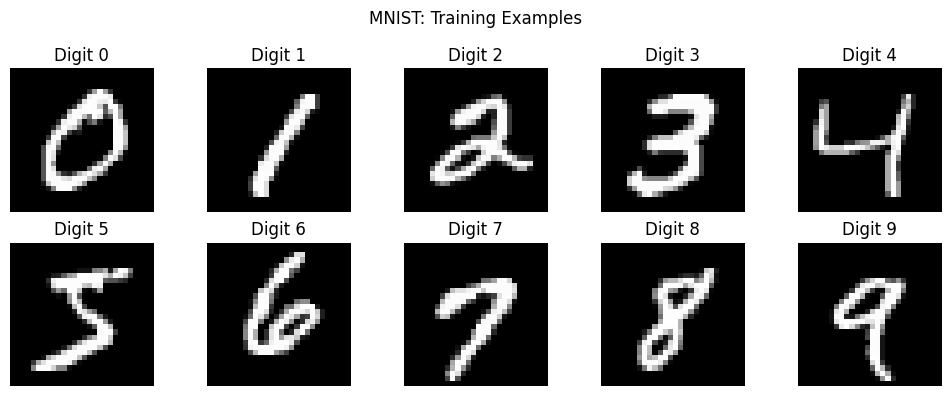

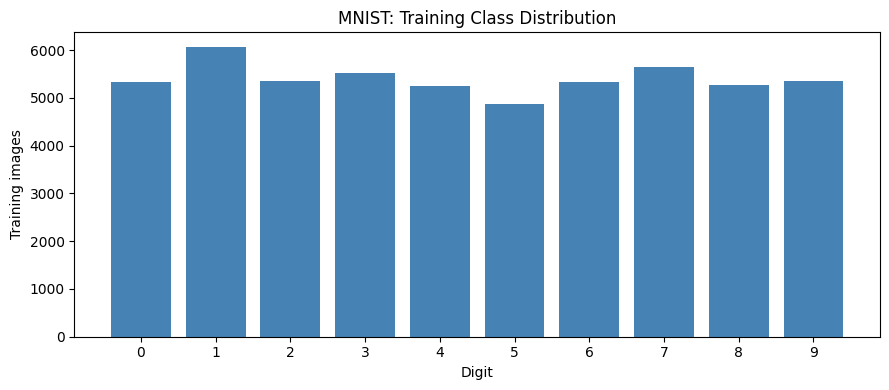

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.flat):
    index = train_indices[np.flatnonzero(official_train_labels[train_indices] == digit)[0]]
    ax.imshow(official_train_images[index], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Digit {digit}')
    ax.axis('off')
fig.suptitle('MNIST: Training Examples')
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'mnist_training_examples.png', dpi=160, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(class_counts.index, class_counts['train'], color='steelblue')
ax.set(xticks=range(10), xlabel='Digit', ylabel='Training images', title='MNIST: Training Class Distribution')
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'mnist_training_class_distribution.png', dpi=160, bbox_inches='tight')
plt.show()


## 4. Shared input and evaluation conventions

The CNN and scratch ViT start with grayscale pixels divided by 255. This fixed conversion does not estimate statistics from validation or test data. VGG16 and AlexNet will use three channels, resizing, and the normalization specified by their pretrained weights. Faster R-CNN will use its documented detection transforms. The raw images and split indices remain available for these model-specific steps.

Accuracy measures correct digit predictions. Macro-F1 gives equal weight to all ten digits. Classification loss is unweighted cross-entropy; Faster R-CNN detection loss will be reported separately because it includes classification and box-related terms. A missing detection counts as an incorrect prediction, never a discarded example.

Training time excludes data and weight downloads, includes validation within the training loop, and uses CUDA synchronization before and after timing. Record actual epochs, batch size, and GPU for each model. Model and checkpoint selection uses validation only; test evaluation is deferred until all configurations are frozen.


In [6]:
X_train = torch.from_numpy(official_train_images[train_indices]).unsqueeze(1).float().div(255)
y_train = torch.from_numpy(official_train_labels[train_indices].astype(np.int64))
X_validation = torch.from_numpy(official_train_images[validation_indices]).unsqueeze(1).float().div(255)
y_validation = torch.from_numpy(official_train_labels[validation_indices].astype(np.int64))
assert X_train.shape == (54000, 1, 28, 28)
assert X_validation.shape == (6000, 1, 28, 28)
assert y_train.dtype == torch.int64
assert torch.isfinite(X_train).all() and torch.isfinite(X_validation).all()
assert 0 <= X_train.min() <= X_train.max() <= 1

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64,
                          shuffle=True, generator=loader_generator, num_workers=0,
                          worker_init_fn=seed_worker, pin_memory=True)
validation_loader = DataLoader(TensorDataset(X_validation, y_validation), batch_size=64,
                               shuffle=False, num_workers=0, pin_memory=True)

def classification_metrics(y_true, y_pred):
    return {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'macro_f1': float(f1_score(y_true, y_pred, labels=np.arange(10), average='macro', zero_division=0)),
    }

def gpu_time():
    torch.cuda.synchronize(device)
    return time.perf_counter()

print('Training tensors:', X_train.shape, y_train.shape)
print('Validation tensors:', X_validation.shape, y_validation.shape)
print('Input dtype:', X_train.dtype, '| Target dtype:', y_train.dtype)
print('Batches per training epoch:', len(train_loader))
print('PASS: tensors and data loaders ready. No test predictions computed.')


Training tensors: torch.Size([54000, 1, 28, 28]) torch.Size([54000])
Validation tensors: torch.Size([6000, 1, 28, 28]) torch.Size([6000])
Input dtype: torch.float32 | Target dtype: torch.int64
Batches per training epoch: 844
PASS: tensors and data loaders ready. No test predictions computed.


### Faster R-CNN adaptation and setup export

Proposed adaptation: one digit per image, with a derived full-image bounding box. This is not a localization annotation supplied by MNIST. Detector label 0 is background; digit labels 0-9 map to 1-10. Keep the complete detector and use the highest-scoring detection for image classification. Fix its score threshold using validation before the final test. If there is no detection, use an incorrect-prediction sentinel rather than dropping the image.

This is an implementation choice because the assignment does not specify how to adapt MNIST to detection. A clarification from the professor takes precedence. Detector construction and visual checks of these targets belong to Issue 3.


In [7]:
setup_config = {
    'dataset': 'hojjatk/mnist-dataset',
    'seed': SEED,
    'source_sha256': source_hashes,
    'split_sha256': split_hash,
    'partition_sizes': {name: len(labels) for name, labels in split_labels.items()},
    'split_policy': 'Stratified holdout from official train; official test kept separate',
    'cnn_vit_input': 'float32 grayscale pixels / 255; NCHW',
    'class_labels': list(range(10)),
    'metrics': ['accuracy', 'macro_f1', 'loss', 'training_seconds'],
    'selection_data': 'validation only',
    'timing': 'CUDA synchronized; includes per-epoch validation; excludes downloads',
    'faster_rcnn': {
        'box_policy': 'one derived full-image box per image',
        'background_label': 0,
        'digit_to_detector_label': 'digit + 1',
        'image_prediction': 'highest-scoring detection; no detection counts as incorrect',
        'score_threshold': 'to be fixed using validation in Issue 3',
        'loss_note': 'detection loss is not directly comparable to classifier cross-entropy',
    },
    'test_predictions_computed': False,
}
(RESULTS_DIR / 'mnist_setup_config.json').write_text(json.dumps(setup_config, indent=2))
print('Saved setup configuration:', RESULTS_DIR / 'mnist_setup_config.json')
print('PASS: Issue 1 setup cells completed. Review outputs before closing the issue.')


Saved setup configuration: /kaggle/working/results/mnist_setup_config.json
PASS: Issue 1 setup cells completed. Review outputs before closing the issue.


## 5. Model experiment

ImageNet-pretrained VGG16 uses a new ten-class output layer. Two warm-up epochs train that layer only; three fine-tuning epochs update convolution block 5 and the classifier while blocks 1–4 remain frozen. Both phases use the same MNIST split and a global batch size of 32 across two T4 GPUs. The checkpoint is selected by the lowest validation cross-entropy across both phases.

After the Kaggle session restarted, the reporting cells loaded the saved results from attached private datasets. Training and restored-checkpoint verification outputs below are retained from the original session.


In [8]:
from torchvision.models import VGG16_Weights

vgg_weights = VGG16_Weights.IMAGENET1K_V1
vgg_transform = vgg_weights.transforms()

sample_grayscale = X_train[:8]
sample_rgb = sample_grayscale.repeat(1, 3, 1, 1)
sample_vgg = vgg_transform(sample_rgb)

assert sample_rgb.shape == (8, 3, 28, 28)
assert sample_vgg.shape == (8, 3, 224, 224)
assert sample_vgg.dtype == torch.float32
assert torch.isfinite(sample_vgg).all()
assert torch.equal(sample_rgb[:, 0], sample_rgb[:, 1])
assert torch.equal(sample_rgb[:, 1], sample_rgb[:, 2])

print("Pretrained weights:", vgg_weights.name)
print("Transforms:", vgg_transform)
print("Original sample shape:", tuple(sample_grayscale.shape))
print("VGG16 input shape:", tuple(sample_vgg.shape))
print(
    "Normalized pixel range:",
    round(sample_vgg.min().item(), 4),
    round(sample_vgg.max().item(), 4),
)
print("Visible GPUs:", torch.cuda.device_count())
print("PASS: VGG16 input transforms produce finite float32 tensors.")
print("No model training or test evaluation performed.")

Pretrained weights: IMAGENET1K_V1
Transforms: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
Original sample shape: (8, 1, 28, 28)
VGG16 input shape: (8, 3, 224, 224)
Normalized pixel range: -2.1179 2.6395
Visible GPUs: 2
PASS: VGG16 input transforms produce finite float32 tensors.
No model training or test evaluation performed.


In [9]:
from torchvision.models import vgg16

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

vgg_model = vgg16(weights=vgg_weights)

for parameter in vgg_model.parameters():
    parameter.requires_grad = False

vgg_model.classifier[6] = nn.Linear(
    vgg_model.classifier[6].in_features,
    10,
)

vgg_model = vgg_model.to(device)
vgg_criterion = nn.CrossEntropyLoss()

vgg_model.eval()
with torch.no_grad():
    sample_logits = vgg_model(sample_vgg.to(device))
    sample_loss = vgg_criterion(
        sample_logits,
        y_train[:8].to(device),
    )

assert sample_logits.shape == (8, 10)
assert torch.isfinite(sample_logits).all()
assert torch.isfinite(sample_loss)

total_parameters = sum(p.numel() for p in vgg_model.parameters())
trainable_parameters = sum(
    p.numel() for p in vgg_model.parameters() if p.requires_grad
)

print("Final layer:", vgg_model.classifier[6])
print(f"Total parameters: {total_parameters:,}")
print(f"Warm-up trainable parameters: {trainable_parameters:,}")
print("Trainable tensors:")
for name, parameter in vgg_model.named_parameters():
    if parameter.requires_grad:
        print(f"  {name}: {tuple(parameter.shape)}")

print("Output shape:", tuple(sample_logits.shape))
print("Device:", next(vgg_model.parameters()).device)
print("PASS: pretrained VGG16 loaded; ten-class forward pass is finite.")
print("No optimizer updates or test evaluation performed.")

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 254MB/s] 


Final layer: Linear(in_features=4096, out_features=10, bias=True)
Total parameters: 134,301,514
Warm-up trainable parameters: 40,970
Trainable tensors:
  classifier.6.weight: (10, 4096)
  classifier.6.bias: (10,)
Output shape: (8, 10)
Device: cuda:0
PASS: pretrained VGG16 loaded; ten-class forward pass is finite.
No optimizer updates or test evaluation performed.


In [10]:
vgg_config = {
    "seed": SEED,
    "architecture": "VGG16",
    "pretrained_weights": vgg_weights.name,
    "num_classes": 10,
    "resize_size": 256,
    "crop_size": 224,
    "normalization_mean": list(vgg_transform.mean),
    "normalization_std": list(vgg_transform.std),
    "optimizer": "Adam",
    "global_batch_size": 32,
    "warmup_epochs": 2,
    "warmup_learning_rate": 0.001,
    "warmup_trainable_layers": ["classifier.6"],
    "finetune_epochs": 3,
    "finetune_backbone_learning_rate": 0.00001,
    "finetune_classifier_learning_rate": 0.0001,
    "finetune_trainable_layers": ["features.24 onwards", "classifier"],
    "loss": "CrossEntropyLoss",
    "checkpoint_selection": "lowest validation cross-entropy across both phases",
    "checkpoint_tie_break": "earliest epoch",
    "split_sha256": split_hash,
}

assert isinstance(vgg_model.features[24], nn.Conv2d)
assert vgg_model.features[24].in_channels == 512
assert vgg_model.features[24].out_channels == 512

vgg_block5_parameters = sum(
    p.numel() for p in vgg_model.features[24:].parameters()
)
vgg_classifier_parameters = sum(
    p.numel() for p in vgg_model.classifier.parameters()
)

print(json.dumps(vgg_config, indent=2))
print(f"\nFine-tuning parameters: "
      f"{vgg_block5_parameters + vgg_classifier_parameters:,}")
print("GPU strategy will be finalized after benchmarking.")
print("Timing will exclude weight downloads.")
print("PASS: training schedule defined; model remains in warm-up configuration.")
print("No optimizer updates or test evaluation performed.")

{
  "seed": 42,
  "architecture": "VGG16",
  "pretrained_weights": "IMAGENET1K_V1",
  "num_classes": 10,
  "resize_size": 256,
  "crop_size": 224,
  "normalization_mean": [
    0.485,
    0.456,
    0.406
  ],
  "normalization_std": [
    0.229,
    0.224,
    0.225
  ],
  "optimizer": "Adam",
  "global_batch_size": 32,
  "warmup_epochs": 2,
  "warmup_learning_rate": 0.001,
  "warmup_trainable_layers": [
    "classifier.6"
  ],
  "finetune_epochs": 3,
  "finetune_backbone_learning_rate": 1e-05,
  "finetune_classifier_learning_rate": 0.0001,
  "finetune_trainable_layers": [
    "features.24 onwards",
    "classifier"
  ],
  "loss": "CrossEntropyLoss",
  "checkpoint_selection": "lowest validation cross-entropy across both phases",
  "checkpoint_tie_break": "earliest epoch",
  "split_sha256": "d42d6480e8042889f5d4e6ae98011dc1f7014582fc33baf093d8a5d847f395f4"
}

Fine-tuning parameters: 126,666,250
GPU strategy will be finalized after benchmarking.
Timing will exclude weight downloads.
PASS

In [11]:
vgg_train_dataset = TensorDataset(X_train, y_train)
vgg_validation_dataset = TensorDataset(X_validation, y_validation)

vgg_loader_generator = torch.Generator().manual_seed(SEED)

vgg_train_loader = DataLoader(
    vgg_train_dataset,
    batch_size=vgg_config["global_batch_size"],
    shuffle=True,
    generator=vgg_loader_generator,
    num_workers=0,
    pin_memory=True,
)

vgg_train_eval_loader = DataLoader(
    vgg_train_dataset,
    batch_size=vgg_config["global_batch_size"],
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

vgg_validation_loader = DataLoader(
    vgg_validation_dataset,
    batch_size=vgg_config["global_batch_size"],
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

def prepare_vgg_inputs(images, target_device):
    images = images.to(target_device, non_blocking=True)
    return vgg_transform(images.repeat(1, 3, 1, 1))

with torch.no_grad():
    prepared_sample = prepare_vgg_inputs(X_train[:8], device)

assert prepared_sample.shape == (8, 3, 224, 224)
assert prepared_sample.device == next(vgg_model.parameters()).device
assert torch.isfinite(prepared_sample).all()
assert torch.allclose(
    prepared_sample.cpu(),
    sample_vgg.cpu(),
    atol=1e-5,
    rtol=1e-5,
)

print("Training images:", len(vgg_train_dataset))
print("Validation images:", len(vgg_validation_dataset))
print("Global batch size:", vgg_config["global_batch_size"])
print("Training batches per epoch:", len(vgg_train_loader))
print("Validation batches:", len(vgg_validation_loader))
print("Prepared sample shape:", tuple(prepared_sample.shape))
print("Preprocessing device:", prepared_sample.device)
print("PASS: batch preprocessing agrees with the checked sample transforms.")
print("No optimizer updates or test evaluation performed.")

del prepared_sample

Training images: 54000
Validation images: 6000
Global batch size: 32
Training batches per epoch: 1688
Validation batches: 188
Prepared sample shape: (8, 3, 224, 224)
Preprocessing device: cuda:0
PASS: batch preprocessing agrees with the checked sample transforms.
No optimizer updates or test evaluation performed.


In [12]:
def evaluate_vgg(model, loader):
    previous_training_mode = model.training
    model.eval()
    model_device = next(model.parameters()).device

    loss_sum = torch.zeros((), device=model_device, dtype=torch.float64)
    sample_count = 0
    collected_labels = []
    collected_predictions = []

    try:
        with torch.inference_mode():
            for images, labels in loader:
                inputs = prepare_vgg_inputs(images, model_device)
                labels = labels.to(model_device, non_blocking=True)

                logits = model(inputs)
                batch_loss = nn.functional.cross_entropy(
                    logits, labels, reduction="sum"
                )

                if not torch.isfinite(batch_loss):
                    raise RuntimeError("Non-finite VGG16 evaluation loss.")

                loss_sum += batch_loss.double()
                sample_count += labels.size(0)
                collected_labels.append(labels.cpu())
                collected_predictions.append(logits.argmax(dim=1).cpu())
    finally:
        model.train(previous_training_mode)

    if sample_count == 0:
        raise ValueError("The evaluation loader contains no samples.")

    true_labels = torch.cat(collected_labels).numpy()
    predictions = torch.cat(collected_predictions).numpy()

    metrics = {
        "loss": loss_sum.item() / sample_count,
        "accuracy": accuracy_score(true_labels, predictions),
        "macro_f1": f1_score(
            true_labels,
            predictions,
            labels=np.arange(10),
            average="macro",
            zero_division=0,
        ),
    }

    return metrics, true_labels, predictions


print("Evaluation function ready.")
print("Loss: sample-weighted mean cross-entropy.")
print("Metrics: accuracy and macro-F1 across all ten digits.")
print("Evaluation disables dropout and restores the previous model mode.")
print("No training or test evaluation performed.")

Evaluation function ready.
Loss: sample-weighted mean cross-entropy.
Metrics: accuracy and macro-F1 across all ten digits.
Evaluation disables dropout and restores the previous model mode.
No training or test evaluation performed.


In [13]:
def benchmark_vgg_phase(name, fine_tuning, warmup_steps=1, timed_steps=3):
    for parameter in vgg_model.parameters():
        parameter.requires_grad = False

    trainable_modules = (
        [vgg_model.features[24:], vgg_model.classifier]
        if fine_tuning
        else [vgg_model.classifier[6]]
    )
    for module in trainable_modules:
        for parameter in module.parameters():
            parameter.requires_grad = True

    vgg_model.train()
    torch.cuda.reset_peak_memory_stats(device)

    def backward_pass():
        vgg_model.zero_grad(set_to_none=True)
        inputs = prepare_vgg_inputs(benchmark_images, device)
        logits = vgg_model(inputs)
        loss = vgg_criterion(logits, benchmark_labels)
        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite loss during {name} benchmark.")
        loss.backward()

    for _ in range(warmup_steps):
        backward_pass()

    torch.cuda.synchronize(device)
    start = time.perf_counter()

    for _ in range(timed_steps):
        backward_pass()

    torch.cuda.synchronize(device)
    seconds_per_batch = (time.perf_counter() - start) / timed_steps

    peak_gib = torch.cuda.max_memory_allocated(device) / 1024**3
    trainable_bytes = sum(
        p.numel() * p.element_size()
        for p in vgg_model.parameters()
        if p.requires_grad
    )

    vgg_model.zero_grad(set_to_none=True)

    return {
        "phase": name,
        "seconds_per_batch": seconds_per_batch,
        "peak_allocated_GiB": peak_gib,
        "estimated_Adam_moments_GiB": 2 * trainable_bytes / 1024**3,
    }


benchmark_images = X_train[:vgg_config["global_batch_size"]]
benchmark_labels = y_train[:vgg_config["global_batch_size"]].to(device)

original_flags = [p.requires_grad for p in vgg_model.parameters()]
original_mode = vgg_model.training

try:
    with torch.random.fork_rng(devices=[device.index]):
        torch.manual_seed(SEED)
        torch.cuda.manual_seed_all(SEED)

        benchmark_rows = [
            benchmark_vgg_phase("Warm-up", fine_tuning=False),
            benchmark_vgg_phase("Fine-tuning", fine_tuning=True),
        ]

        vgg_model.eval()
        with torch.inference_mode():
            for _ in range(2):
                logits = vgg_model(
                    prepare_vgg_inputs(benchmark_images, device)
                )

            torch.cuda.synchronize(device)
            start = time.perf_counter()

            for _ in range(3):
                logits = vgg_model(
                    prepare_vgg_inputs(benchmark_images, device)
                )
                nn.functional.cross_entropy(logits, benchmark_labels).item()
                logits.argmax(dim=1).cpu()

            torch.cuda.synchronize(device)
            evaluation_seconds_per_batch = (
                time.perf_counter() - start
            ) / 3
finally:
    vgg_model.zero_grad(set_to_none=True)
    for parameter, flag in zip(vgg_model.parameters(), original_flags):
        parameter.requires_grad = flag
    vgg_model.train(original_mode)

benchmark_table = pd.DataFrame(benchmark_rows)
evaluation_batches = (
    len(vgg_train_eval_loader) + len(vgg_validation_loader)
)
benchmark_table["estimated_epoch_minutes"] = (
    benchmark_table["seconds_per_batch"] * len(vgg_train_loader)
    + evaluation_seconds_per_batch * evaluation_batches
) / 60

display(benchmark_table.round(4))

estimated_total_minutes = (
    benchmark_table.iloc[0]["estimated_epoch_minutes"]
    * vgg_config["warmup_epochs"]
    + benchmark_table.iloc[1]["estimated_epoch_minutes"]
    * vgg_config["finetune_epochs"]
)

print(f"Evaluation seconds per batch: {evaluation_seconds_per_batch:.4f}")
print(f"Estimated five-epoch run: {estimated_total_minutes:.2f} minutes")
print("Estimates include full training and validation evaluation each epoch.")
print("They exclude optimizer steps, checkpoint writes, and loader overhead.")
print("Adam moment storage is an estimate, not a measured memory peak.")
print("PASS: benchmark finished without optimizer updates.")
print("Original trainable layers and model mode restored.")
print("Test set remains unevaluated.")

,phase,seconds_per_batch,peak_allocated_GiB,estimated_Adam_moments_GiB,estimated_epoch_minutes
0,Warm-up,0.1508,3.0243,0.0003,9.1611
1,Fine-tuning,0.1719,3.0243,0.9437,9.7548


Evaluation seconds per batch: 0.1573
Estimated five-epoch run: 47.59 minutes
Estimates include full training and validation evaluation each epoch.
They exclude optimizer steps, checkpoint writes, and loader overhead.
Adam moment storage is an estimate, not a measured memory peak.
PASS: benchmark finished without optimizer updates.
Original trainable layers and model mode restored.
Test set remains unevaluated.


In [14]:
import os
import subprocess
import sys
import textwrap

assert torch.cuda.device_count() >= 2, "Enable two GPUs in Kaggle."
assert torch.distributed.is_available()
assert torch.distributed.is_nccl_available()

vgg_worker_dir = Path("/kaggle/working/vgg16_ddp")
vgg_worker_dir.mkdir(parents=True, exist_ok=True)

probe_path = vgg_worker_dir / "communication_probe.py"
probe_path.write_text(
    textwrap.dedent("""
        import os
        import torch
        import torch.distributed as dist

        local_rank = int(os.environ["LOCAL_RANK"])
        torch.cuda.set_device(local_rank)
        device = torch.device("cuda", local_rank)

        dist.init_process_group(
            backend="nccl",
            device_id=device,
        )

        try:
            value = torch.tensor(
                [float(dist.get_rank() + 1)],
                device=device,
            )
            dist.all_reduce(value)

            assert value.item() == 3.0
            print(
                f"Rank {dist.get_rank()} | "
                f"GPU {local_rank}: {torch.cuda.get_device_name(local_rank)} | "
                f"All-reduce result: {value.item()}",
                flush=True,
            )
        finally:
            dist.destroy_process_group()
    """),
    encoding="utf-8",
)

probe_environment = os.environ.copy()
probe_environment["OMP_NUM_THREADS"] = "1"

probe_result = subprocess.run(
    [
        sys.executable,
        "-m",
        "torch.distributed.run",
        "--standalone",
        "--nnodes=1",
        "--nproc_per_node=2",
        str(probe_path),
    ],
    env=probe_environment,
    capture_output=True,
    text=True,
    timeout=120,
)

print(probe_result.stdout)
if probe_result.stderr:
    print(probe_result.stderr)

if probe_result.returncode != 0:
    raise RuntimeError("Two-GPU communication check failed.")

print("PASS: two-GPU NCCL communication.")
print("Planned global batch size: 32; batch size per GPU: 16.")
print("Notebook model weights remain unchanged.")
print("No training or test evaluation performed.")

Rank 1 | GPU 1: Tesla T4 | All-reduce result: 3.0Rank 0 | GPU 0: Tesla T4 | All-reduce result: 3.0


PASS: two-GPU NCCL communication.
Planned global batch size: 32; batch size per GPU: 16.
Notebook model weights remain unchanged.
No training or test evaluation performed.


In [15]:
vgg_ddp_config = {
    **vgg_config,
    "world_size": 2,
    "gpus_used": 2,
    "batch_size_per_gpu": 16,
    "precision": "float32",
    "training_evaluation": "all original training images",
    "timing_scope": (
        "training, per-epoch training and validation evaluation, "
        "and checkpoint writes; excludes worker startup and input loading"
    ),
}

assert (
    vgg_ddp_config["batch_size_per_gpu"]
    * vgg_ddp_config["world_size"]
    == vgg_ddp_config["global_batch_size"]
)
assert len(X_train) == len(y_train) == 54000
assert len(X_validation) == len(y_validation) == 6000

worker_arrays = {
    "train_images": X_train.detach().cpu().numpy(),
    "train_labels": y_train.detach().cpu().numpy(),
    "validation_images": X_validation.detach().cpu().numpy(),
    "validation_labels": y_validation.detach().cpu().numpy(),
}

for name, array in worker_arrays.items():
    np.save(vgg_worker_dir / f"{name}.npy", array, allow_pickle=False)

vgg_model = vgg_model.cpu()
initial_weights_path = vgg_worker_dir / "initial_weights.pt"
torch.save(vgg_model.state_dict(), initial_weights_path)

(vgg_worker_dir / "config.json").write_text(
    json.dumps(vgg_ddp_config, indent=2),
    encoding="utf-8",
)

assert initial_weights_path.is_file()
assert sum(
    p.numel() for p in vgg_model.parameters() if p.requires_grad
) == 40970

torch.cuda.empty_cache()

print("Worker input directory:", vgg_worker_dir)
print("Training samples:", len(X_train))
print("Validation samples:", len(X_validation))
print("Global batch size:", vgg_ddp_config["global_batch_size"])
print("Batch size per GPU:", vgg_ddp_config["batch_size_per_gpu"])
print(
    "Initial weights file size:",
    round(initial_weights_path.stat().st_size / 1024**2, 2),
    "MiB",
)
print("Notebook model device:", next(vgg_model.parameters()).device)
print("Split SHA256:", vgg_ddp_config["split_sha256"])
print("PASS: worker inputs and initial weights saved.")
print("No training performed; no test data exported.")

Worker input directory: /kaggle/working/vgg16_ddp
Training samples: 54000
Validation samples: 6000
Global batch size: 32
Batch size per GPU: 16
Initial weights file size: 512.33 MiB
Notebook model device: cpu
Split SHA256: d42d6480e8042889f5d4e6ae98011dc1f7014582fc33baf093d8a5d847f395f4
PASS: worker inputs and initial weights saved.
No training performed; no test data exported.


In [16]:
%%writefile /kaggle/working/vgg16_ddp/worker.py
import argparse
import csv
import gc
import json
import os
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.distributed as dist
from torch import nn
from torch.nn.parallel import DistributedDataParallel as DDP
from torch.utils.data import DataLoader, DistributedSampler, Subset, TensorDataset
from torchvision.models import VGG16_Weights, vgg16


def synchronize():
    torch.cuda.synchronize()
    dist.barrier()


def prepare(images, device, transform):
    return transform(
        images.to(device, non_blocking=True).repeat(1, 3, 1, 1)
    )


def configure_phase(model, phase, config):
    for parameter in model.parameters():
        parameter.requires_grad = False

    if phase == "warmup":
        for parameter in model.classifier[6].parameters():
            parameter.requires_grad = True

        groups = [{
            "params": model.classifier[6].parameters(),
            "lr": config["warmup_learning_rate"],
        }]
    else:
        for parameter in model.features[24:].parameters():
            parameter.requires_grad = True
        for parameter in model.classifier.parameters():
            parameter.requires_grad = True

        groups = [
            {
                "params": model.features[24:].parameters(),
                "lr": config["finetune_backbone_learning_rate"],
            },
            {
                "params": model.classifier.parameters(),
                "lr": config["finetune_classifier_learning_rate"],
            },
        ]

    return torch.optim.Adam(groups, foreach=False)


def metrics_from_confusion(confusion):
    matrix = confusion.cpu().numpy().astype(np.float64)
    true_counts = matrix.sum(axis=1)
    predicted_counts = matrix.sum(axis=0)
    correct = np.diag(matrix)
    denominator = true_counts + predicted_counts

    f1 = np.divide(
        2 * correct,
        denominator,
        out=np.zeros(10, dtype=np.float64),
        where=denominator > 0,
    )
    return {
        "accuracy": float(correct.sum() / matrix.sum()),
        "macro_f1": float(f1.mean()),
    }


def evaluate(model, loader, device, transform, expected_samples):
    previous_mode = model.training
    model.eval()

    totals = torch.zeros(2, dtype=torch.float64, device=device)
    confusion = torch.zeros((10, 10), dtype=torch.int64, device=device)

    try:
        with torch.inference_mode():
            for images, labels in loader:
                labels = labels.to(device, non_blocking=True)
                logits = model(prepare(images, device, transform))
                loss = nn.functional.cross_entropy(
                    logits, labels, reduction="sum"
                )

                totals[0] += loss.double()
                totals[1] += labels.numel()
                predictions = logits.argmax(dim=1)
                confusion += torch.bincount(
                    labels * 10 + predictions, minlength=100
                ).reshape(10, 10)

        dist.all_reduce(totals)
        dist.all_reduce(confusion)

        assert int(totals[1].item()) == expected_samples
        assert int(confusion.sum().item()) == expected_samples
        assert torch.isfinite(totals[0])

        return {
            "loss": float((totals[0] / totals[1]).item()),
            **metrics_from_confusion(confusion),
        }
    finally:
        model.train(previous_mode)


def write_history(path, history):
    with path.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(history[0]))
        writer.writeheader()
        writer.writerows(history)


def benchmark(model, dataset, transform, device, config, rank):
    batch_size = config["batch_size_per_gpu"]
    start_index = rank * batch_size
    images = dataset.tensors[0][start_index:start_index + batch_size]
    labels = dataset.tensors[1][start_index:start_index + batch_size].to(device)

    rows = []
    for phase in ("warmup", "finetune"):
        optimizer = configure_phase(model, phase, config)
        distributed_model = DDP(
            model,
            device_ids=[device.index],
            broadcast_buffers=False,
        )
        distributed_model.train()
        torch.cuda.reset_peak_memory_stats(device)

        def backward_pass():
            optimizer.zero_grad(set_to_none=True)
            logits = distributed_model(prepare(images, device, transform))
            loss = nn.functional.cross_entropy(logits, labels)
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite benchmark loss.")
            loss.backward()

        backward_pass()
        synchronize()
        started = time.perf_counter()

        for _ in range(3):
            backward_pass()

        synchronize()
        elapsed = torch.tensor(
            (time.perf_counter() - started) / 3, device=device
        )
        dist.all_reduce(elapsed, op=dist.ReduceOp.MAX)

        peak = torch.tensor(
            torch.cuda.max_memory_allocated(device) / 1024**3,
            device=device,
        )
        dist.all_reduce(peak, op=dist.ReduceOp.MAX)

        rows.append({
            "phase": phase,
            "seconds_per_global_batch": elapsed.item(),
            "peak_allocated_GiB": peak.item(),
        })

        optimizer.zero_grad(set_to_none=True)
        del distributed_model, optimizer
        gc.collect()
        torch.cuda.empty_cache()

    model.eval()
    with torch.inference_mode():
        model(prepare(images, device, transform))
        synchronize()
        started = time.perf_counter()

        for _ in range(3):
            logits = model(prepare(images, device, transform))
            nn.functional.cross_entropy(logits, labels).item()
            logits.argmax(dim=1).cpu()

        synchronize()
        elapsed = torch.tensor(
            (time.perf_counter() - started) / 3, device=device
        )
        dist.all_reduce(elapsed, op=dist.ReduceOp.MAX)

    evaluation_batch_seconds = elapsed.item()
    training_batches = (
        len(dataset) // config["world_size"] + batch_size - 1
    ) // batch_size
    validation_batches = (
        6000 // config["world_size"] + batch_size - 1
    ) // batch_size

    estimated_total = 0.0
    for row in rows:
        minutes = (
            row["seconds_per_global_batch"] * training_batches
            + evaluation_batch_seconds
            * (training_batches + validation_batches)
        ) / 60
        row["estimated_epoch_minutes"] = minutes
        estimated_total += minutes * config[f"{row['phase']}_epochs"]

    if rank == 0:
        print(json.dumps(rows, indent=2), flush=True)
        print(
            f"Evaluation seconds per global batch: "
            f"{evaluation_batch_seconds:.4f}",
            flush=True,
        )
        print(
            f"Estimated five-epoch run: {estimated_total:.2f} minutes",
            flush=True,
        )
        print(
            "Estimate excludes optimizer steps, loader overhead, "
            "checkpoint writes, and full metric aggregation.",
            flush=True,
        )
        print(
            "PASS: distributed benchmark completed without optimizer updates.",
            flush=True,
        )


def train(model, train_loader, sampler, train_eval_loader,
          validation_loader, transform, device, config, rank):
    results_dir = Path("/kaggle/working/results")
    checkpoint_dir = Path("/kaggle/working/checkpoints")

    if rank == 0:
        results_dir.mkdir(parents=True, exist_ok=True)
        checkpoint_dir.mkdir(parents=True, exist_ok=True)

    synchronize()
    training_started = time.perf_counter()
    history = []
    best_loss = float("inf")
    best_epoch = None
    best_phase = None
    best_metrics = None
    epoch = 0

    for phase in ("warmup", "finetune"):
        optimizer = configure_phase(model, phase, config)
        distributed_model = DDP(
            model,
            device_ids=[device.index],
            broadcast_buffers=False,
        )

        if rank == 0:
            count = sum(
                p.numel() for p in model.parameters() if p.requires_grad
            )
            print(
                f"\nPhase: {phase} | Trainable parameters: {count:,}",
                flush=True,
            )

        for phase_epoch in range(1, config[f"{phase}_epochs"] + 1):
            epoch += 1
            sampler.set_epoch(epoch - 1)
            synchronize()
            epoch_started = time.perf_counter()
            distributed_model.train()

            for images, labels in train_loader:
                labels = labels.to(device, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)

                logits = distributed_model(
                    prepare(images, device, transform)
                )
                loss = nn.functional.cross_entropy(logits, labels)
                if not torch.isfinite(loss):
                    raise RuntimeError(f"Non-finite loss at epoch {epoch}.")

                loss.backward()
                optimizer.step()

            optimizer.zero_grad(set_to_none=True)

            train_metrics = evaluate(
                model, train_eval_loader, device, transform, 54000
            )
            validation_metrics = evaluate(
                model, validation_loader, device, transform, 6000
            )

            if validation_metrics["loss"] < best_loss:
                best_loss = validation_metrics["loss"]
                best_epoch = epoch
                best_phase = phase
                best_metrics = {
                    "train": train_metrics,
                    "validation": validation_metrics,
                }

                if rank == 0:
                    state = {
                        name: value.detach().cpu().clone()
                        for name, value in model.state_dict().items()
                    }
                    torch.save(
                        {
                            "model_state_dict": state,
                            "config": config,
                            "selected_epoch": best_epoch,
                            "selected_phase": best_phase,
                            "metrics": best_metrics,
                            "split_sha256": config["split_sha256"],
                        },
                        checkpoint_dir / "vgg16_best.pt",
                    )
                    del state

            synchronize()
            epoch_seconds = time.perf_counter() - epoch_started

            record = {
                "epoch": epoch,
                "phase": phase,
                "phase_epoch": phase_epoch,
                **{f"train_{k}": v for k, v in train_metrics.items()},
                **{
                    f"validation_{k}": v
                    for k, v in validation_metrics.items()
                },
                "epoch_seconds": epoch_seconds,
            }
            history.append(record)

            if rank == 0:
                write_history(
                    results_dir / "vgg16_training_history.csv", history
                )
                print(
                    f"Epoch {epoch}/5 | {phase} | "
                    f"Loss: {train_metrics['loss']:.4f} / "
                    f"{validation_metrics['loss']:.4f} | "
                    f"Accuracy: {train_metrics['accuracy']:.4f} / "
                    f"{validation_metrics['accuracy']:.4f} | "
                    f"Macro-F1: {train_metrics['macro_f1']:.4f} / "
                    f"{validation_metrics['macro_f1']:.4f} | "
                    f"Time: {epoch_seconds:.1f}s",
                    flush=True,
                )

        del distributed_model, optimizer
        gc.collect()
        torch.cuda.empty_cache()

    synchronize()
    training_seconds = time.perf_counter() - training_started

    if rank == 0:
        run_config = {
            **config,
            "selected_epoch": best_epoch,
            "selected_phase": best_phase,
            "selected_metrics": best_metrics,
            "training_seconds": training_seconds,
            "test_evaluated": False,
        }
        (results_dir / "vgg16_run_config.json").write_text(
            json.dumps(run_config, indent=2), encoding="utf-8"
        )
        print(
            f"\nTotal training time: {training_seconds / 60:.2f} minutes",
            flush=True,
        )
        print(f"Selected epoch: {best_epoch} ({best_phase})", flush=True)
        print(
            "PASS: training finished; best validation-loss checkpoint saved.",
            flush=True,
        )
        print("Test set remains unevaluated.", flush=True)


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--mode", choices=["benchmark", "train"], required=True)
    args = parser.parse_args()

    root = Path(__file__).resolve().parent
    config = json.loads((root / "config.json").read_text(encoding="utf-8"))
    local_rank = int(os.environ["LOCAL_RANK"])
    torch.cuda.set_device(local_rank)
    device = torch.device("cuda", local_rank)
    dist.init_process_group(backend="nccl", device_id=device)

    try:
        rank = dist.get_rank()
        world_size = dist.get_world_size()
        assert world_size == config["world_size"] == 2

        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

        def load_dataset(prefix):
            images = torch.from_numpy(
                np.load(root / f"{prefix}_images.npy", allow_pickle=False)
            )
            labels = torch.from_numpy(
                np.load(root / f"{prefix}_labels.npy", allow_pickle=False)
            )
            assert images.dtype == torch.float32
            assert labels.dtype == torch.int64
            return TensorDataset(images, labels)

        train_dataset = load_dataset("train")
        validation_dataset = load_dataset("validation")
        assert len(train_dataset) == 54000
        assert len(validation_dataset) == 6000
        assert len(train_dataset) % world_size == 0

        model = vgg16(weights=None)
        model.classifier[6] = nn.Linear(4096, 10)
        initial_state = torch.load(
            root / "initial_weights.pt",
            map_location="cpu",
            weights_only=True,
        )
        model.load_state_dict(initial_state)
        del initial_state
        model = model.to(device)

        seed = config["seed"] + rank
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)
        torch.cuda.manual_seed(seed)

        transform = VGG16_Weights.IMAGENET1K_V1.transforms()

        if args.mode == "benchmark":
            benchmark(model, train_dataset, transform, device, config, rank)
            return

        sampler = DistributedSampler(
            train_dataset,
            num_replicas=world_size,
            rank=rank,
            shuffle=True,
            seed=config["seed"],
            drop_last=False,
        )
        loader_options = {
            "batch_size": config["batch_size_per_gpu"],
            "num_workers": 0,
            "pin_memory": True,
        }
        train_loader = DataLoader(
            train_dataset, sampler=sampler, **loader_options
        )
        train_eval_loader = DataLoader(
            Subset(train_dataset, range(rank, len(train_dataset), world_size)),
            shuffle=False,
            **loader_options,
        )
        validation_loader = DataLoader(
            Subset(
                validation_dataset,
                range(rank, len(validation_dataset), world_size),
            ),
            shuffle=False,
            **loader_options,
        )

        train(
            model, train_loader, sampler, train_eval_loader,
            validation_loader, transform, device, config, rank,
        )
    finally:
        dist.destroy_process_group()


if __name__ == "__main__":
    main()

Writing /kaggle/working/vgg16_ddp/worker.py


In [17]:
vgg_benchmark_command = [
    sys.executable,
    "-m",
    "torch.distributed.run",
    "--standalone",
    "--nnodes=1",
    "--nproc_per_node=2",
    str(vgg_worker_dir / "worker.py"),
    "--mode",
    "benchmark",
]

vgg_worker_environment = os.environ.copy()
vgg_worker_environment["OMP_NUM_THREADS"] = "1"
vgg_worker_environment["PYTHONUNBUFFERED"] = "1"

vgg_benchmark_log = vgg_worker_dir / "benchmark.log"

with vgg_benchmark_log.open("w", encoding="utf-8") as log:
    process = subprocess.Popen(
        vgg_benchmark_command,
        env=vgg_worker_environment,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )

    try:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()

        return_code = process.wait()
    finally:
        if process.poll() is None:
            process.terminate()
            try:
                process.wait(timeout=15)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait()
        process.stdout.close()

if return_code != 0:
    raise RuntimeError(
        f"Distributed benchmark failed. Inspect {vgg_benchmark_log}"
    )

print("PASS: benchmark process completed successfully.")
print("Full training has not started.")

[
  {
    "phase": "warmup",
    "seconds_per_global_batch": 0.08686086535453796,
    "peak_allocated_GiB": 1.7719826698303223,
    "estimated_epoch_minutes": 5.042004803319772
  },
  {
    "phase": "finetune",
    "seconds_per_global_batch": 0.2023628056049347,
    "peak_allocated_GiB": 2.716202735900879,
    "estimated_epoch_minutes": 8.291459389030933
  }
]
Evaluation seconds per global batch: 0.0831
Estimated five-epoch run: 34.96 minutes
Estimate excludes optimizer steps, loader overhead, checkpoint writes, and full metric aggregation.
PASS: distributed benchmark completed without optimizer updates.
PASS: benchmark process completed successfully.
Full training has not started.


In [18]:
vgg_training_command = [
    sys.executable,
    "-m",
    "torch.distributed.run",
    "--standalone",
    "--nnodes=1",
    "--nproc_per_node=2",
    str(vgg_worker_dir / "worker.py"),
    "--mode",
    "train",
]

vgg_training_log = vgg_worker_dir / "training.log"

with vgg_training_log.open("w", encoding="utf-8") as log:
    process = subprocess.Popen(
        vgg_training_command,
        env=vgg_worker_environment,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )

    try:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()

        return_code = process.wait()
    finally:
        if process.poll() is None:
            process.terminate()
            try:
                process.wait(timeout=15)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait()
        process.stdout.close()

if return_code != 0:
    raise RuntimeError(
        f"Distributed training failed. Inspect {vgg_training_log}"
    )

vgg_checkpoint_path = Path("/kaggle/working/checkpoints/vgg16_best.pt")
assert vgg_checkpoint_path.is_file()

print("Saved checkpoint:", vgg_checkpoint_path)
print(
    "Checkpoint size:",
    round(vgg_checkpoint_path.stat().st_size / 1024**2, 2),
    "MiB",
)
print("PASS: distributed training completed and checkpoint exists.")


Phase: warmup | Trainable parameters: 40,970
Epoch 1/5 | warmup | Loss: 0.2582 / 0.2673 | Accuracy: 0.9253 / 0.9220 | Macro-F1: 0.9244 / 0.9210 | Time: 308.2s
Epoch 2/5 | warmup | Loss: 0.2522 / 0.2651 | Accuracy: 0.9226 / 0.9203 | Macro-F1: 0.9213 / 0.9189 | Time: 306.5s

Phase: finetune | Trainable parameters: 126,666,250
Epoch 3/5 | finetune | Loss: 0.0182 / 0.0499 | Accuracy: 0.9949 / 0.9870 | Macro-F1: 0.9948 / 0.9870 | Time: 575.2s
Epoch 4/5 | finetune | Loss: 0.0074 / 0.0435 | Accuracy: 0.9979 / 0.9910 | Macro-F1: 0.9980 / 0.9910 | Time: 576.8s
Epoch 5/5 | finetune | Loss: 0.0050 / 0.0669 | Accuracy: 0.9984 / 0.9910 | Macro-F1: 0.9985 / 0.9910 | Time: 575.5s

Total training time: 39.04 minutes
Selected epoch: 4 (finetune)
PASS: training finished; best validation-loss checkpoint saved.
Test set remains unevaluated.
Saved checkpoint: /kaggle/working/checkpoints/vgg16_best.pt
Checkpoint size: 512.33 MiB
PASS: distributed training completed and checkpoint exists.


In [23]:
vgg_run_config = json.loads(
    (RESULTS_DIR / "vgg16_run_config.json").read_text(encoding="utf-8")
)
vgg_history_df = pd.read_csv(RESULTS_DIR / "vgg16_training_history.csv")

vgg_checkpoint_path = Path("/kaggle/working/checkpoints/vgg16_best.pt")
vgg_checkpoint = torch.load(
    vgg_checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

assert vgg_checkpoint["split_sha256"] == split_hash
assert vgg_run_config["split_sha256"] == split_hash
assert vgg_run_config["test_evaluated"] is False

vgg_selected_epoch = int(vgg_checkpoint["selected_epoch"])
assert vgg_selected_epoch == vgg_run_config["selected_epoch"]

selected_rows = vgg_history_df.loc[
    vgg_history_df["epoch"] == vgg_selected_epoch
]
assert len(selected_rows) == 1
selected_row = selected_rows.iloc[0]

assert selected_row["phase"] == vgg_checkpoint["selected_phase"]
assert vgg_selected_epoch == int(
    vgg_history_df.loc[
        vgg_history_df["validation_loss"].idxmin(), "epoch"
    ]
)

for split in ("train", "validation"):
    for metric in ("loss", "accuracy", "macro_f1"):
        saved_value = vgg_checkpoint["metrics"][split][metric]
        assert np.isclose(
            saved_value,
            selected_row[f"{split}_{metric}"],
            rtol=1e-8,
            atol=1e-10,
        )
        assert np.isclose(
            saved_value,
            vgg_run_config["selected_metrics"][split][metric],
            rtol=1e-8,
            atol=1e-10,
        )

vgg_model.load_state_dict(vgg_checkpoint["model_state_dict"], strict=True)
vgg_model = vgg_model.to(device)
vgg_model.eval()

vgg_selected_metrics = vgg_checkpoint["metrics"]
del vgg_checkpoint

display(pd.DataFrame([
    {"split": split, **metrics}
    for split, metrics in vgg_selected_metrics.items()
]))

print("Selected epoch:", vgg_selected_epoch)
print("Selected phase:", vgg_run_config["selected_phase"])
print("Training time:", round(vgg_run_config["training_seconds"] / 60, 2), "minutes")
print("Model device:", next(vgg_model.parameters()).device)
print("PASS: selected weights loaded; saved metrics agree with history.")
print("Independent validation prediction verification is next.")
print("Test set remains unevaluated.")

,split,loss,accuracy,macro_f1
0,train,0.007355,0.997926,0.997967
1,validation,0.043520,0.991000,0.991022


Selected epoch: 4
Selected phase: finetune
Training time: 39.04 minutes
Model device: cuda:0
PASS: selected weights loaded; saved metrics agree with history.
Independent validation prediction verification is next.
Test set remains unevaluated.


In [24]:
vgg_validation_metrics, vgg_true_labels, vgg_predictions = evaluate_vgg(
    vgg_model,
    vgg_validation_loader,
)

assert len(vgg_true_labels) == len(vgg_predictions) == 6000
assert np.array_equal(
    vgg_true_labels,
    y_validation.cpu().numpy(),
)

for metric in ("accuracy", "macro_f1"):
    assert np.isclose(
        vgg_validation_metrics[metric],
        vgg_selected_metrics["validation"][metric],
        rtol=0,
        atol=1e-12,
    ), f"Restored predictions differ for {metric}."

assert np.isclose(
    vgg_validation_metrics["loss"],
    vgg_selected_metrics["validation"]["loss"],
    rtol=1e-4,
    atol=1e-6,
), "Restored validation loss differs beyond numerical tolerance."

vgg_validation_predictions_df = pd.DataFrame({
    "source_index": validation_indices,
    "true_digit": vgg_true_labels,
    "predicted_digit": vgg_predictions,
    "correct": vgg_true_labels == vgg_predictions,
})

assert vgg_validation_predictions_df["source_index"].is_unique

vgg_validation_predictions_df.to_csv(
    RESULTS_DIR / "vgg16_validation_predictions.csv",
    index=False,
)

vgg_metrics_df = pd.DataFrame([
    {"model": "VGG16", "split": split, **metrics}
    for split, metrics in vgg_selected_metrics.items()
])
vgg_metrics_df.to_csv(RESULTS_DIR / "vgg16_metrics.csv", index=False)

print("Verified validation metrics:", vgg_validation_metrics)
print("Validation errors:", int((vgg_true_labels != vgg_predictions).sum()))
print("Saved validation predictions:", len(vgg_validation_predictions_df))
print("PASS: restored predictions reproduce the selected checkpoint metrics.")
print("Test set remains unevaluated.")

Verified validation metrics: {'loss': 0.04352009744637144, 'accuracy': 0.991, 'macro_f1': 0.9910219845330339}
Validation errors: 54
Saved validation predictions: 6000
PASS: restored predictions reproduce the selected checkpoint metrics.
Test set remains unevaluated.


vgg16_run_config.json: /kaggle/input/datasets/soulaimanebenayad/vgg16-results/vgg16_run_config.json
vgg16_training_history.csv: /kaggle/input/datasets/soulaimanebenayad/vgg16-results/vgg16_training_history.csv
vgg16_validation_predictions.csv: /kaggle/input/datasets/soulaimanebenayad/vgg16-results/vgg16_validation_predictions.csv


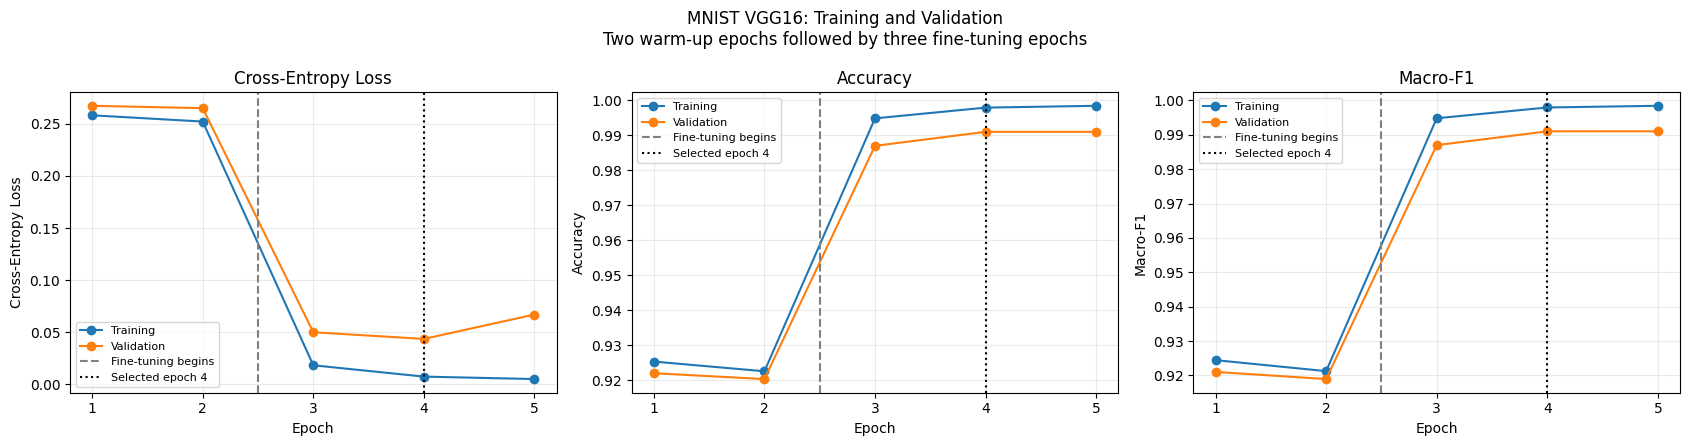

PASS: saved results loaded and learning curves created.
No training or test evaluation performed.


In [2]:
from pathlib import Path
import json
import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS_DIR = Path("/kaggle/working/results")
PLOTS_DIR = Path("/kaggle/working/plots")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

required_files = [
    "vgg16_run_config.json",
    "vgg16_training_history.csv",
    "vgg16_validation_predictions.csv",
]

input_paths = {}
for filename in required_files:
    matches = sorted(Path("/kaggle/input").rglob(filename))
    if len(matches) != 1:
        raise RuntimeError(
            f"Expected one copy of {filename}; found {len(matches)}."
        )
    input_paths[filename] = matches[0]
    shutil.copy2(matches[0], RESULTS_DIR / filename)
    print(f"{filename}: {matches[0]}")

vgg_run_config = json.loads(
    input_paths["vgg16_run_config.json"].read_text(encoding="utf-8")
)
vgg_history_df = pd.read_csv(
    input_paths["vgg16_training_history.csv"]
)
vgg_validation_predictions_df = pd.read_csv(
    input_paths["vgg16_validation_predictions.csv"]
)

expected_split_hash = (
    "d42d6480e8042889f5d4e6ae98011dc1f7014582fc33baf093d8a5d847f395f4"
)
assert vgg_run_config["split_sha256"] == expected_split_hash
assert vgg_run_config["test_evaluated"] is False
assert vgg_history_df["epoch"].tolist() == [1, 2, 3, 4, 5]
assert len(vgg_validation_predictions_df) == 6000
assert vgg_validation_predictions_df["source_index"].is_unique

vgg_selected_epoch = int(vgg_run_config["selected_epoch"])
warmup_epochs = int(vgg_run_config["warmup_epochs"])

assert vgg_selected_epoch == int(
    vgg_history_df.loc[
        vgg_history_df["validation_loss"].idxmin(), "epoch"
    ]
)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for ax, metric, title in zip(
    axes,
    ["loss", "accuracy", "macro_f1"],
    ["Cross-Entropy Loss", "Accuracy", "Macro-F1"],
):
    ax.plot(
        vgg_history_df["epoch"],
        vgg_history_df[f"train_{metric}"],
        marker="o",
        label="Training",
    )
    ax.plot(
        vgg_history_df["epoch"],
        vgg_history_df[f"validation_{metric}"],
        marker="o",
        label="Validation",
    )
    ax.axvline(
        warmup_epochs + 0.5,
        color="gray",
        linestyle="--",
        label="Fine-tuning begins",
    )
    ax.axvline(
        vgg_selected_epoch,
        color="black",
        linestyle=":",
        label=f"Selected epoch {vgg_selected_epoch}",
    )
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.set_xticks(vgg_history_df["epoch"])
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

fig.suptitle(
    "MNIST VGG16: Training and Validation\n"
    "Two warm-up epochs followed by three fine-tuning epochs"
)
fig.tight_layout()
fig.savefig(
    PLOTS_DIR / "vgg16_learning_curves.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("PASS: saved results loaded and learning curves created.")
print("No training or test evaluation performed.")

,precision,recall,f1-score,support
digit_or_summary,,,,
0,0.9866,0.9949,0.9907,592.000
1,1.0000,0.9881,0.9940,674.000
2,0.9818,0.9933,0.9875,596.000
3,0.9902,0.9918,0.9910,613.000
4,0.9881,0.9932,0.9906,584.000
5,0.9981,0.9926,0.9954,542.000
6,0.9983,0.9966,0.9975,592.000
7,0.9826,0.9920,0.9873,627.000
8,0.9881,0.9966,0.9923,585.000


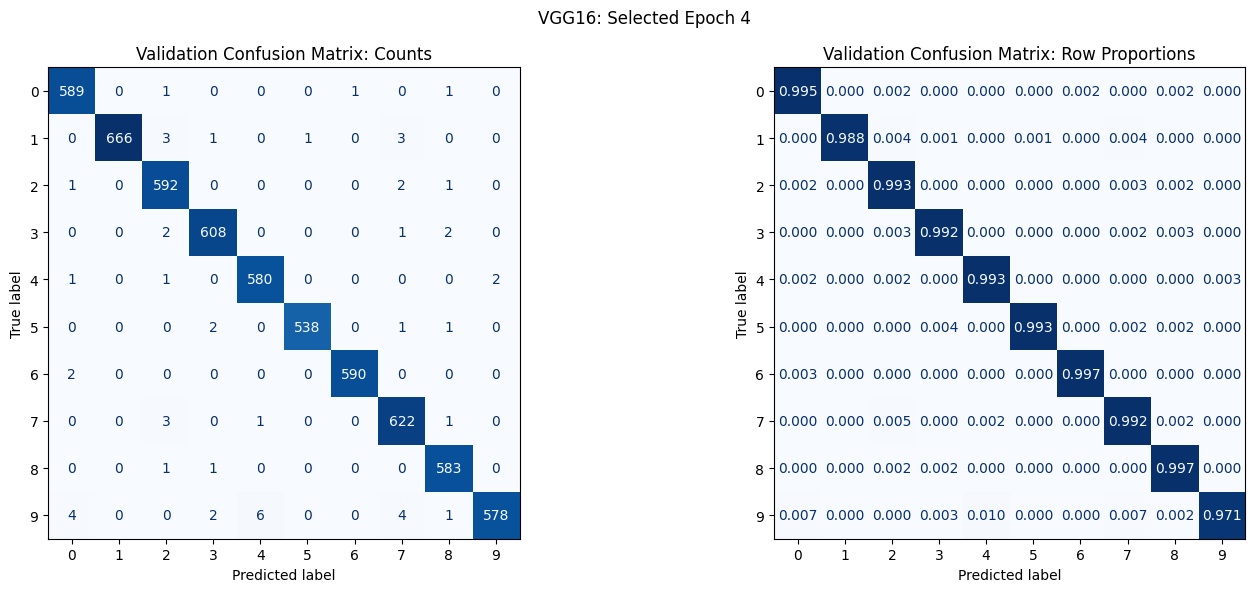

Validation accuracy: 0.991
Validation macro-F1: 0.9910219845330339
Validation errors: 54
PASS: saved predictions reproduce the selected validation metrics.
No training or test evaluation performed.


In [3]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
    f1_score,
)

vgg_true_labels = vgg_validation_predictions_df["true_digit"].to_numpy()
vgg_predictions = vgg_validation_predictions_df["predicted_digit"].to_numpy()

assert np.isin(vgg_true_labels, np.arange(10)).all()
assert np.isin(vgg_predictions, np.arange(10)).all()

verified_accuracy = accuracy_score(vgg_true_labels, vgg_predictions)
verified_macro_f1 = f1_score(
    vgg_true_labels,
    vgg_predictions,
    labels=np.arange(10),
    average="macro",
    zero_division=0,
)

saved_metrics = vgg_run_config["selected_metrics"]["validation"]
assert np.isclose(verified_accuracy, saved_metrics["accuracy"], atol=1e-12, rtol=0)
assert np.isclose(verified_macro_f1, saved_metrics["macro_f1"], atol=1e-12, rtol=0)

vgg_report = classification_report(
    vgg_true_labels,
    vgg_predictions,
    labels=np.arange(10),
    target_names=[str(digit) for digit in range(10)],
    output_dict=True,
    zero_division=0,
)
vgg_report_df = pd.DataFrame(vgg_report).T
vgg_report_df.index.name = "digit_or_summary"
vgg_report_df.to_csv(
    RESULTS_DIR / "vgg16_validation_classification_report.csv"
)

display(vgg_report_df.round(4))

counts = confusion_matrix(
    vgg_true_labels, vgg_predictions, labels=np.arange(10)
)
proportions = counts / counts.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, matrix, title, value_format in [
    (axes[0], counts, "Validation Confusion Matrix: Counts", "d"),
    (
        axes[1],
        proportions,
        "Validation Confusion Matrix: Row Proportions",
        ".3f",
    ),
]:
    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=np.arange(10),
    ).plot(
        ax=ax,
        cmap="Blues",
        values_format=value_format,
        colorbar=False,
    )
    ax.set_title(title)

fig.suptitle(f"VGG16: Selected Epoch {vgg_selected_epoch}")
fig.tight_layout()
fig.savefig(
    PLOTS_DIR / "vgg16_validation_confusion.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("Validation accuracy:", verified_accuracy)
print("Validation macro-F1:", verified_macro_f1)
print("Validation errors:", int((vgg_true_labels != vgg_predictions).sum()))
print("PASS: saved predictions reproduce the selected validation metrics.")
print("No training or test evaluation performed.")

In [4]:
comparison_files = [
    "cnn_config.json",
    "cnn_validation_predictions.csv",
    "faster_rcnn_run_config.json",
    "faster_rcnn_metrics.csv",
    "faster_rcnn_validation_predictions.csv",
]

comparison_paths = {}
for filename in comparison_files:
    matches = sorted(Path("/kaggle/input").rglob(filename))
    if len(matches) != 1:
        raise RuntimeError(
            f"Expected one copy of {filename}; found {len(matches)}."
        )
    comparison_paths[filename] = matches[0]

cnn_saved_config = json.loads(
    comparison_paths["cnn_config.json"].read_text(encoding="utf-8")
)
rcnn_saved_config = json.loads(
    comparison_paths["faster_rcnn_run_config.json"].read_text(encoding="utf-8")
)
rcnn_saved_metrics = pd.read_csv(
    comparison_paths["faster_rcnn_metrics.csv"]
)
rcnn_validation_rows = rcnn_saved_metrics.loc[
    rcnn_saved_metrics["split"] == "validation"
]
assert len(rcnn_validation_rows) == 1
rcnn_validation_metrics = rcnn_validation_rows.iloc[0]

model_configs = {
    "CNN": cnn_saved_config,
    "Faster R-CNN": rcnn_saved_config,
    "VGG16": vgg_run_config,
}
model_predictions = {
    "CNN": pd.read_csv(comparison_paths["cnn_validation_predictions.csv"]),
    "Faster R-CNN": pd.read_csv(
        comparison_paths["faster_rcnn_validation_predictions.csv"]
    ),
    "VGG16": vgg_validation_predictions_df.copy(),
}
expected_metrics = {
    "CNN": cnn_saved_config["validation_metrics"],
    "Faster R-CNN": rcnn_validation_metrics,
    "VGG16": vgg_run_config["selected_metrics"]["validation"],
}
loss_types = {
    "CNN": "Cross-entropy",
    "Faster R-CNN": "Total detection loss",
    "VGG16": "Cross-entropy",
}

reference = None
comparison_rows = []

for model_name, predictions in model_predictions.items():
    config = model_configs[model_name]
    assert config["split_sha256"] == expected_split_hash
    assert config["test_evaluated"] is False

    columns = ["source_index", "true_digit", "predicted_digit"]
    assert predictions[columns].notna().all().all()
    assert len(predictions) == 6000
    assert predictions["source_index"].is_unique

    predictions = predictions.sort_values("source_index").reset_index(drop=True)
    assert np.isin(predictions["true_digit"], np.arange(10)).all()
    allowed_predictions = (
        np.arange(-1, 10) if model_name == "Faster R-CNN" else np.arange(10)
    )
    assert np.isin(predictions["predicted_digit"], allowed_predictions).all()

    if reference is None:
        reference = predictions[["source_index", "true_digit"]].copy()
    else:
        assert np.array_equal(
            reference.to_numpy(),
            predictions[["source_index", "true_digit"]].to_numpy(),
        ), f"Validation image IDs or labels differ for {model_name}."

    accuracy = accuracy_score(
        predictions["true_digit"], predictions["predicted_digit"]
    )
    macro_f1 = f1_score(
        predictions["true_digit"],
        predictions["predicted_digit"],
        labels=np.arange(10),
        average="macro",
        zero_division=0,
    )

    for metric, value in [("accuracy", accuracy), ("macro_f1", macro_f1)]:
        assert np.isclose(
            value, expected_metrics[model_name][metric], atol=1e-12, rtol=0
        ), f"Saved {metric} differs for {model_name}."

    comparison_rows.append({
        "model": model_name,
        "selected_epoch": int(config["selected_epoch"]),
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "errors": int(
            (predictions["true_digit"] != predictions["predicted_digit"]).sum()
        ),
        "missing_detections": int((predictions["predicted_digit"] == -1).sum()),
        "validation_loss": float(expected_metrics[model_name]["loss"]),
        "loss_type": loss_types[model_name],
        "training_seconds": float(config["training_seconds"]),
        "training_minutes": float(config["training_seconds"]) / 60,
        "gpus_used": int(config["gpus_used"]),
    })

vgg_comparison_df = pd.DataFrame(comparison_rows)
vgg_comparison_df.to_csv(
    RESULTS_DIR / "cnn_faster_rcnn_vgg16_comparison.csv",
    index=False,
)

pd.DataFrame([
    {"model": "VGG16", "split": split, **metrics}
    for split, metrics in vgg_run_config["selected_metrics"].items()
]).to_csv(RESULTS_DIR / "vgg16_metrics.csv", index=False)

comparison_protocol = {
    "split_sha256": expected_split_hash,
    "validation_samples": 6000,
    "matching_image_ids_and_labels": True,
    "checkpoint_selection": {
        name: config["checkpoint_selection"]
        for name, config in model_configs.items()
    },
    "timing_scopes": {
        name: config["timing_scope"]
        for name, config in model_configs.items()
    },
    "limitations": [
        "Recorded times use different GPU counts and evaluation workloads.",
        "Faster R-CNN detection loss differs from classifier cross-entropy.",
        "VGG16 uses ImageNet pretraining and larger input images.",
        "Configurations use different epoch budgets and checkpoint rules.",
        "Results describe one run per model.",
    ],
    "test_evaluated": False,
}
(RESULTS_DIR / "cnn_faster_rcnn_vgg16_protocol.json").write_text(
    json.dumps(comparison_protocol, indent=2),
    encoding="utf-8",
)

display(vgg_comparison_df.round(6))

print("PASS: identical validation image IDs and labels across all three models.")
print("PASS: recomputed metrics match the saved experiments.")
print("Comparison table and protocol saved.")
print("Detection loss must be interpreted separately.")
print("Recorded run times are not a controlled speed benchmark.")
print("No training or test evaluation performed.")

,model,selected_epoch,accuracy,macro_f1,errors,missing_detections,validation_loss,loss_type,training_seconds,training_minutes,gpus_used
0,CNN,10,0.991500,0.991446,51,0,0.03526,Cross-entropy,32.100712,0.535012,1
1,Faster R-CNN,9,0.988833,0.988829,67,0,0.03469,Total detection loss,3432.163973,57.202733,2
2,VGG16,4,0.991000,0.991022,54,0,0.04352,Cross-entropy,2342.617489,39.043625,2


PASS: identical validation image IDs and labels across all three models.
PASS: recomputed metrics match the saved experiments.
Comparison table and protocol saved.
Detection loss must be interpreted separately.
Recorded run times are not a controlled speed benchmark.
No training or test evaluation performed.


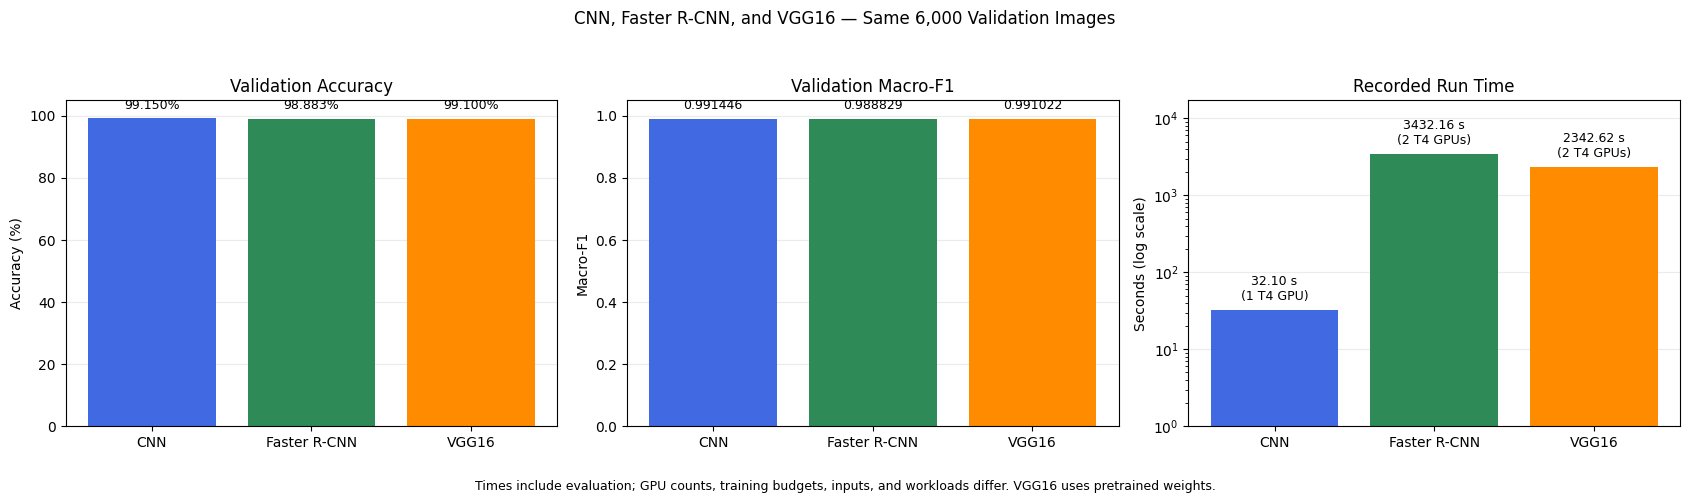

PASS: three-model validation comparison chart saved.
No training or test evaluation performed.


In [5]:
plot_data = vgg_comparison_df.set_index("model").loc[
    ["CNN", "Faster R-CNN", "VGG16"]
].reset_index()

colors = ["royalblue", "seagreen", "darkorange"]
positions = np.arange(len(plot_data))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

panels = [
    ("accuracy", 100, "Validation Accuracy", "Accuracy (%)"),
    ("macro_f1", 1, "Validation Macro-F1", "Macro-F1"),
    ("training_seconds", 1, "Recorded Run Time", "Seconds (log scale)"),
]

for ax, (column, multiplier, title, ylabel) in zip(axes, panels):
    values = plot_data[column].to_numpy() * multiplier
    ax.bar(positions, values, color=colors)
    ax.set_xticks(positions, plot_data["model"])
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

    if column == "accuracy":
        ax.set_ylim(0, 105)
    elif column == "macro_f1":
        ax.set_ylim(0, 1.05)
    else:
        ax.set_yscale("log")
        ax.set_ylim(1, values.max() * 5)

    for position, value, gpu_count in zip(
        positions, values, plot_data["gpus_used"]
    ):
        if column == "accuracy":
            label = f"{value:.3f}%"
        elif column == "macro_f1":
            label = f"{value:.6f}"
        else:
            label = f"{value:.2f} s\n({gpu_count} T4 GPU{'s' if gpu_count > 1 else ''})"

        ax.annotate(
            label,
            (position, value),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
        )

fig.suptitle(
    "CNN, Faster R-CNN, and VGG16 — Same 6,000 Validation Images"
)
fig.text(
    0.5,
    0.02,
    "Times include evaluation; GPU counts, training budgets, inputs, and "
    "workloads differ. VGG16 uses pretrained weights.",
    ha="center",
    fontsize=9,
)
fig.tight_layout(rect=[0, 0.07, 1, 0.94])
fig.savefig(
    PLOTS_DIR / "cnn_faster_rcnn_vgg16_comparison.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("PASS: three-model validation comparison chart saved.")
print("No training or test evaluation performed.")

### Findings

VGG16 was initialized with ImageNet-pretrained weights. Two warm-up epochs trained only the new ten-class output layer. Three fine-tuning epochs then updated the last convolution block and the classifier, while the first four convolution blocks remained frozen.

Fine-tuning improved validation accuracy from about 92% to 99.10%. Epoch 4 was selected by the lowest validation cross-entropy. Its restored checkpoint achieved 0.991022 macro-F1 and made 54 errors among 6,000 validation images. Digit 9 had the lowest recall.

At epoch 5, training loss continued to decrease while validation loss increased, although validation accuracy remained at 99.10%. This suggests increasing overfitting and supports retaining epoch 4.

On the same validation images, the CNN made 51 errors, VGG16 made 54, and Faster R-CNN made 67. VGG16 therefore achieved similar classification performance to the small CNN, but required a much longer recorded run: 39.04 minutes on two T4 GPUs, compared with 32.10 seconds on one T4 for the CNN.

These results describe the tested configurations. Pretraining, input sizes, GPU counts, training budgets, and evaluation workloads differ. Faster R-CNN also uses a different loss objective. The comparison does not establish general superiority, and the test set remains unevaluated.